# Homework 5 - Classification Challenge: Learn a New Algorithm and Beat the Baseline!

Author: Vadim Egorov

**Objective:** learn how XGBoost works, apply it to a real dataset, and compare it with Logistic Regression and a Decision Tree.

**Dataset:** [Gas Sensor Array Drift at Different Concentrations](https://archive.ics.uci.edu/dataset/270/gas+sensor+array+drift+dataset+at+different+concentrations) (UCI Machine Learning Repository).

## 1. Imports + Setup

In [1]:
# ucimlrepo isn't preinstalled in Google Colab
%pip install -q ucimlrepo

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ucimlrepo import fetch_ucirepo
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             balanced_accuracy_score, confusion_matrix, classification_report)
from xgboost import XGBClassifier

# Larger default size for all plots
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['font.size'] = 12

## 2. Load Data

In [3]:
# Fetch dataset 
gas_sensor_array_drift_at_different_concentrations = fetch_ucirepo(id=270) 

# Data as pandas dataframes ``
X = gas_sensor_array_drift_at_different_concentrations.data.features
y = gas_sensor_array_drift_at_different_concentrations.data.targets

In [4]:
y

,class
1;10.000000,1:15596.162100
1;20.000000,1:26402.070400
1;30.000000,1:42103.582000
1;40.000000,1:42825.988300
1;50.000000,1:58151.175700
...,...
5;50,1:28929.5108
4;250,1:40392.123
5;600,1:183271.5898
4;150,1:29059.8516


### 2.1 Fix the parsing
`ucimlrepo` doesn't parse the raw libsvm files correctly: gas and concentration end up in the index, feature values are strings like `"2:1.868245"`, and the columns are shifted by one.

In [5]:
raw = gas_sensor_array_drift_at_different_concentrations.data.original
raw.iloc[:3, :4]

,class,Feature1,Feature2,Feature3
1;10.000000,1:15596.162100,2:1.868245,3:2.371604,4:2.803678
1;20.000000,1:26402.070400,2:2.532401,3:5.411209,4:6.509906
1;30.000000,1:42103.582000,2:3.454189,3:8.198175,4:10.508439


In [6]:
# Drop the empty last column, then strip the "k:" prefix and convert to numbers
features = raw.drop(columns=['Feature128']).apply(lambda col: col.str.split(':').str[1].astype(float))

# 8 features per sensor x 16 sensors (order from the UCI description)
feature_types = ['DR', 'DR_norm', 'EMAi0.001', 'EMAi0.01', 'EMAi0.1', 'EMAd0.001', 'EMAd0.01', 'EMAd0.1']
features.columns = [f'S{sensor}_{ftype}' for sensor in range(1, 17) for ftype in feature_types]

# The index holds "gas;concentration"
gas_conc = raw.index.to_series().str.split(';', expand=True)
gas_names = {1: 'Ethanol', 2: 'Ethylene', 3: 'Ammonia', 4: 'Acetaldehyde', 5: 'Acetone', 6: 'Toluene'}

df = features.reset_index(drop=True)
df['gas'] = gas_conc[0].astype(int).map(gas_names).values
df['concentration'] = gas_conc[1].astype(float).values

df

,S1_DR,S1_DR_norm,S1_EMAi0.001,S1_EMAi0.01,S1_EMAi0.1,S1_EMAd0.001,S1_EMAd0.01,S1_EMAd0.1,S2_DR,S2_DR_norm,...,S16_DR,S16_DR_norm,S16_EMAi0.001,S16_EMAi0.01,S16_EMAi0.1,S16_EMAd0.001,S16_EMAd0.01,S16_EMAd0.1,gas,concentration
0,15596.1621,1.868245,2.371604,2.803678,7.512213,-2.739388,-3.344671,-4.847512,15326.6914,1.768526,...,3037.0390,3.972203,0.527291,0.728443,1.445783,-0.545079,-0.902241,-2.654529,Ethanol,10.0
1,26402.0704,2.532401,5.411209,6.509906,7.658469,-4.722217,-5.817651,-7.518333,23855.7812,2.164706,...,4176.4453,4.281373,0.980205,1.628050,1.951172,-0.889333,-1.323505,-1.749225,Ethanol,20.0
2,42103.5820,3.454189,8.198175,10.508439,11.611003,-7.668313,-9.478675,-12.230939,37562.3008,2.840403,...,5914.6685,5.396827,1.403973,2.476956,3.039841,-1.334558,-1.993659,-2.348370,Ethanol,30.0
3,42825.9883,3.451192,12.113940,16.266853,39.910056,-7.849409,-9.689894,-11.921704,38379.0664,2.851173,...,6147.4744,5.501071,1.981933,3.569823,4.049197,-1.432205,-2.146158,-2.488957,Ethanol,40.0
4,58151.1757,4.194839,11.455096,15.715298,17.654915,-11.083364,-13.580692,-16.407848,51975.5899,3.480866,...,8158.6449,7.174334,1.993808,3.829303,4.402448,-1.930107,-2.931265,-4.088756,Ethanol,50.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
13905,28929.5108,3.309200,4.393300,5.057000,9.423300,-3.879400,-5.415100,-15.933500,42203.8965,3.377800,...,5480.6582,2.851000,1.046500,2.039900,5.341900,-0.842830,-1.407700,-4.447900,Acetone,50.0
13906,40392.1230,3.280000,10.268900,13.585900,20.979000,-8.173200,-10.859100,-31.802700,40322.3164,2.594000,...,15700.0969,5.216200,5.167500,8.995000,11.591700,-4.495400,-7.655300,-12.767100,Acetaldehyde,250.0
13907,183271.5898,15.594500,45.480300,63.877500,81.139600,-29.539100,-47.626600,-329.266900,229854.3418,14.519400,...,50936.2070,17.808000,17.288700,26.789500,33.366100,-15.823700,-28.516200,-56.332800,Acetone,600.0
13908,29059.8516,2.568000,6.714200,8.786500,13.987800,-6.041100,-8.070700,-22.322300,28441.1289,2.069400,...,10079.5098,3.539900,3.266000,6.249900,9.026200,-2.849500,-4.734300,-9.573100,Acetaldehyde,150.0


Each of the 16 sensors gives 8 features: `DR` (resistance change), `DR_norm` (normalized), and `EMAi*` / `EMAd*` (moving-average extremes of the rising and decaying response). `concentration` isn't used as a feature.

## 3. EDA — Exploratory Data Analysis

In [7]:
display(df.shape)
display(df.dtypes.value_counts())

(13910, 130)

float64    129
str          1
Name: count, dtype: int64

### 3.1 Missing values and duplicates

In [8]:
missing_values_num = df.isnull().sum().sum()
duplicate_rows_num = df.duplicated().sum()

print(f"Number of missing values: {missing_values_num}")
print(f"Number of duplicate rows: {duplicate_rows_num}")

Number of missing values: 0
Number of duplicate rows: 0


No missing values and no duplicates.

### 3.2 Target variable: `gas`

In [9]:
class_counts = df['gas'].value_counts()
class_counts

gas
Acetone         3009
Ethylene        2926
Ethanol         2565
Acetaldehyde    1936
Toluene         1833
Ammonia         1641
Name: count, dtype: int64

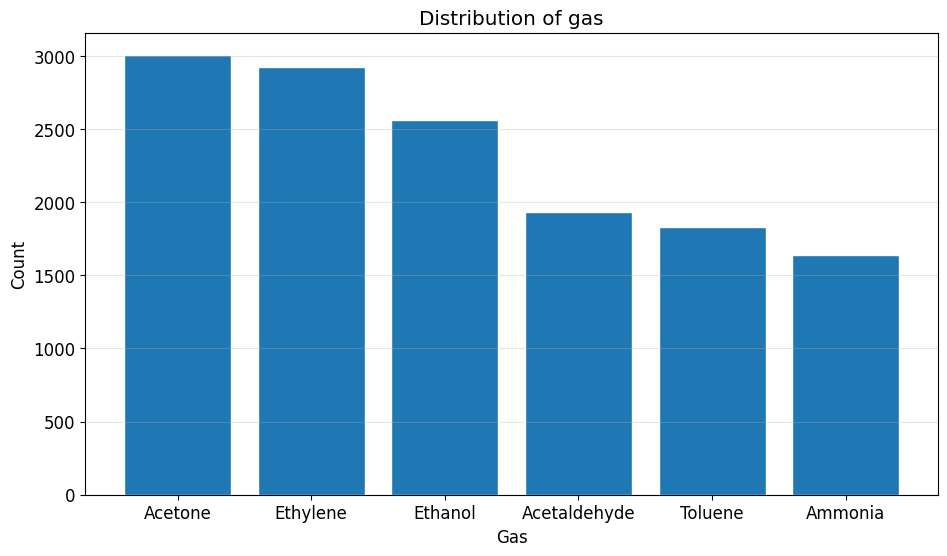

In [10]:
plt.bar(class_counts.index, class_counts.values, edgecolor='white')
plt.xlabel("Gas")
plt.ylabel("Count")
plt.title("Distribution of gas")
plt.grid(axis='y', alpha=0.3)
plt.show()

In [11]:
print(f"Imbalance ratio (largest / smallest class): {class_counts.max() / class_counts.min():.2f}")

Imbalance ratio (largest / smallest class): 1.83


- 6 classes, from 1,641 (Ammonia) to 3,009 (Acetone) measurements.
- Imbalance ratio 1.83 is mild, but balanced accuracy and macro F1 are reported too.

### 3.3 Feature scales

In [12]:
df.describe().T[['mean', 'std', 'min', 'max']].head(8)

,mean,std,min,max
S1_DR,50435.066174,69844.785952,-16757.598600,670687.347700
S1_DR_norm,6.638156,13.486391,0.088287,1339.879283
S1_EMAi0.001,12.936688,17.610061,0.000100,167.079751
S1_EMAi0.01,18.743953,24.899450,0.000100,226.619457
S1_EMAi0.1,26.890695,38.107685,0.000100,993.605306
S1_EMAd0.001,-9.158655,12.729206,-131.332873,-0.006941
S1_EMAd0.01,-14.402383,21.304606,-227.627758,22.201589
S1_EMAd0.1,-59.927598,131.017675,-1664.735576,115.273147


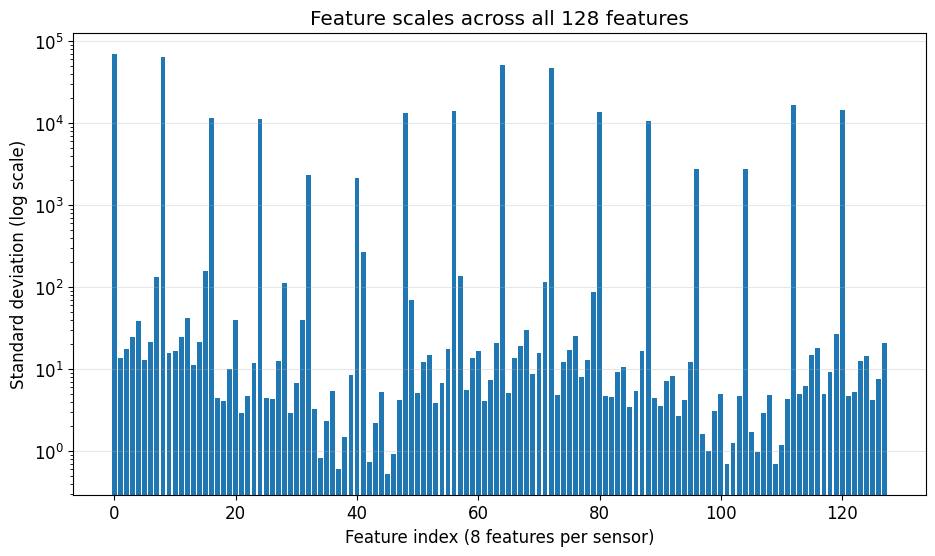

In [13]:
feature_std = df.drop(columns=['gas', 'concentration']).std()

plt.bar(range(len(feature_std)), feature_std.values)
plt.yscale('log')
plt.xlabel("Feature index (8 features per sensor)")
plt.ylabel("Standard deviation (log scale)")
plt.title("Feature scales across all 128 features")
plt.grid(axis='y', alpha=0.3)
plt.show()

- Feature scales differ hugely (std from below 1 to about 10⁴), with long tails.
- **Logistic Regression needs scaling.** Tree models split on thresholds, so they don't.

### 3.4 Correlation between features

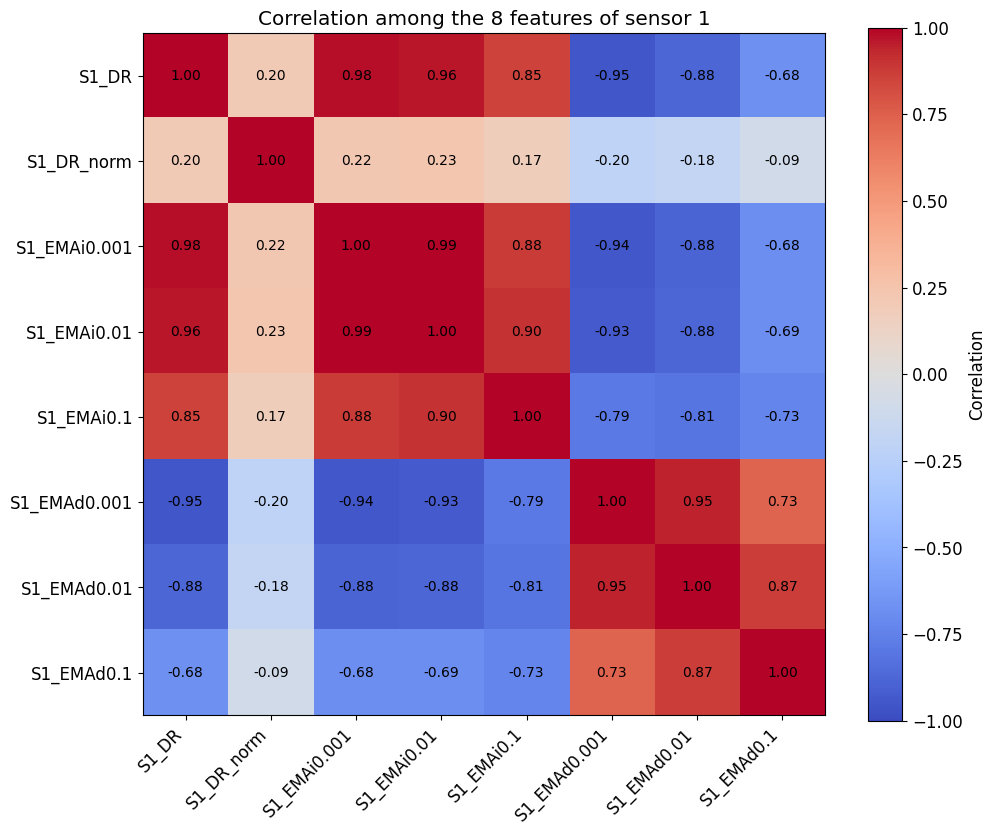

In [14]:
sensor1 = [f'S1_{ftype}' for ftype in feature_types]
feature_corr = df[sensor1].corr()

plt.figure(figsize=(11, 9))
plt.imshow(feature_corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(sensor1)), sensor1, rotation=45, ha='right')
plt.yticks(range(len(sensor1)), sensor1)

# Write the correlation value inside each square
for i in range(len(sensor1)):
    for j in range(len(sensor1)):
        plt.text(j, i, f"{feature_corr.iloc[i, j]:.2f}", ha='center', va='center', fontsize=10)

plt.title("Correlation among the 8 features of sensor 1")
plt.show()

Features within a sensor are strongly correlated (|r| up to 0.95); only `DR_norm` carries different information. This redundancy is fine: L2 regularization and tree splits both handle it.

## 4. Preprocessing

### 4.1 Get X and y

In [15]:
X = df.drop(columns=['gas', 'concentration'])

# XGBoost needs class labels 0..5, so encode the gas names as integers
class_names = sorted(df['gas'].unique())
y = df['gas'].map({name: i for i, name in enumerate(class_names)})

print(dict(enumerate(class_names)))
X.shape, y.shape

{0: 'Acetaldehyde', 1: 'Acetone', 2: 'Ammonia', 3: 'Ethanol', 4: 'Ethylene', 5: 'Toluene'}


((13910, 128), (13910,))

### 4.2 Train/test split
80/20 split, stratified by gas.

In [16]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test: ", X_test.shape)

Train: (11128, 128)
Test:  (2782, 128)


### 4.3 Scaling
Only Logistic Regression is scaled. The scaler sits inside a pipeline, so it's fit on training data only.

### 4.4 Evaluation function
Precision, recall and F1 are macro-averaged, so every gas counts equally.

In [17]:
def evaluate(model_name, y_true, y_pred):
    return {
        'Model': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced accuracy': balanced_accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, average='macro'),
        'Recall': recall_score(y_true, y_pred, average='macro'),
        'F1': f1_score(y_true, y_pred, average='macro'),
        'Test errors': (y_true != y_pred).sum(),
    }

## 5. Model 1: Logistic Regression
### 5.1 Train the model

In [18]:
log_reg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
log_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some 

### 5.2 Evaluate

In [19]:
log_reg_train_pred = log_reg.predict(X_train)
log_reg_test_pred = log_reg.predict(X_test)

log_reg_results = evaluate('Logistic Regression', y_test, log_reg_test_pred)

print("Training accuracy:", accuracy_score(y_train, log_reg_train_pred))
print("Testing accuracy: ", log_reg_results['Accuracy'])
print("Balanced accuracy:", log_reg_results['Balanced accuracy'])
print("Macro F1:         ", log_reg_results['F1'])

Training accuracy: 0.9933501078360891
Testing accuracy:  0.992451473759885
Balanced accuracy: 0.9917790727153429
Macro F1:          0.9923860479253058


- **Test accuracy 99.25%** (21 errors). Training accuracy is 99.34%, so no overfitting.
- The gases are nearly linearly separable, which sets a high bar for XGBoost.

## 6. Model 2: Decision Tree
### 6.1 Train the model
Default settings: the tree grows until every leaf is pure.

In [20]:
tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current

### 6.2 Evaluate

In [21]:
tree_train_pred = tree.predict(X_train)
tree_test_pred = tree.predict(X_test)

tree_results = evaluate('Decision Tree', y_test, tree_test_pred)

print("Training accuracy:", accuracy_score(y_train, tree_train_pred))
print("Testing accuracy: ", tree_results['Accuracy'])
print("Balanced accuracy:", tree_results['Balanced accuracy'])
print("Macro F1:         ", tree_results['F1'])
print("Tree depth:       ", tree.get_depth())
print("Number of leaves: ", tree.get_n_leaves())

Training accuracy: 1.0
Testing accuracy:  0.9723220704529115
Balanced accuracy: 0.9702193515853094
Macro F1:          0.9705321723691983
Tree depth:        22
Number of leaves:  267


- **Test accuracy 97.23%** (77 errors), the weakest model.
- 100% training accuracy with depth 22 and 267 leaves: the tree **overfits**.

## 7. Model 3: XGBoost
XGBoost adds shallow trees one at a time, each fitting the errors of the trees before it. Parameters are tuned with 3-fold stratified CV on the training data only.

*Takes several minutes to run in Colab.*

In [22]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

### 7.1 Number of trees and learning rate
Validation error is tracked after every tree for three learning rates.

In [23]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

learning_rates = [0.03, 0.1, 0.3]
val_curves = {}

for lr in learning_rates:
    model = XGBClassifier(
        n_estimators=400,
        learning_rate=lr,
        eval_metric='merror',  # multiclass error rate = 1 - accuracy
        random_state=42
    )
    model.fit(X_tr, y_tr, eval_set=[(X_val, y_val)], verbose=False)
    val_curves[lr] = model.evals_result()['validation_0']['merror']

    best_round = int(np.argmin(val_curves[lr])) + 1
    print(f"learning_rate = {lr}: lowest validation error {min(val_curves[lr]):.4f} at {best_round} trees")

learning_rate = 0.03: lowest validation error 0.0072 at 248 trees


learning_rate = 0.1: lowest validation error 0.0072 at 137 trees


learning_rate = 0.3: lowest validation error 0.0072 at 34 trees


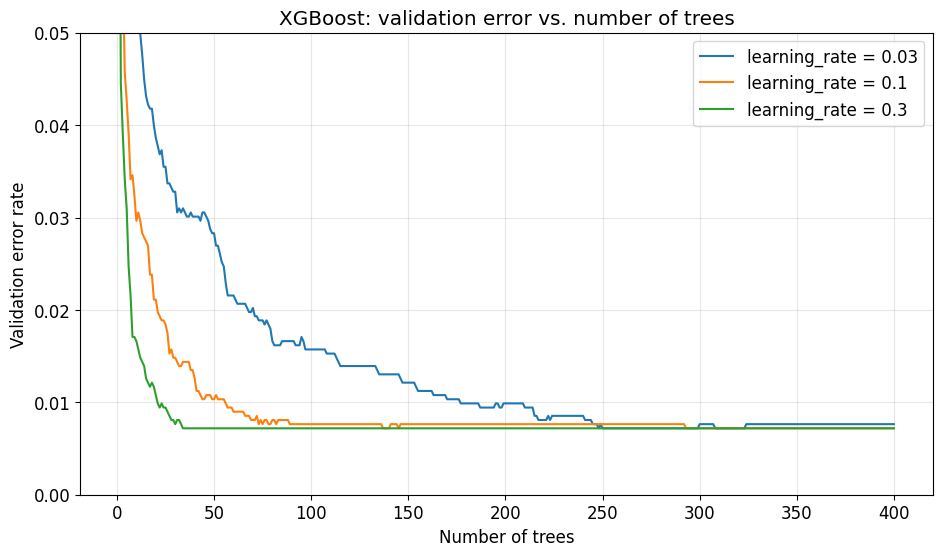

In [24]:
for lr in learning_rates:
    plt.plot(range(1, 401), val_curves[lr], label=f'learning_rate = {lr}')

plt.ylim(0, 0.05)
plt.xlabel("Number of trees")
plt.ylabel("Validation error rate")
plt.title("XGBoost: validation error vs. number of trees")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

- All three learning rates reach the same lowest validation error (0.72%), at about 34 (0.3), 137 (0.1) and 248 (0.03) trees.
- **Chosen: `learning_rate = 0.1` with 300 trees.**

### 7.2 Tree depth

In [25]:
n_trees = 300
depths = [2, 3, 4, 6, 8]

depth_search = GridSearchCV(
    XGBClassifier(n_estimators=n_trees, learning_rate=0.1, random_state=42),
    {'max_depth': depths},
    cv=cv,
    scoring='f1_macro',
    return_train_score=True
)
depth_search.fit(X_train, y_train)

depth_results = pd.DataFrame({
    'max_depth': depths,
    'train_f1': depth_search.cv_results_['mean_train_score'],
    'cv_f1': depth_search.cv_results_['mean_test_score'],
    'cv_f1_std': depth_search.cv_results_['std_test_score'],
})
depth_results

,max_depth,train_f1,cv_f1,cv_f1_std
0,2,0.998706,0.989833,0.001792
1,3,1.000000,0.992609,0.000993
2,4,1.000000,0.992213,0.001065
3,6,1.000000,0.991869,0.000563
4,8,1.000000,0.991960,0.001089


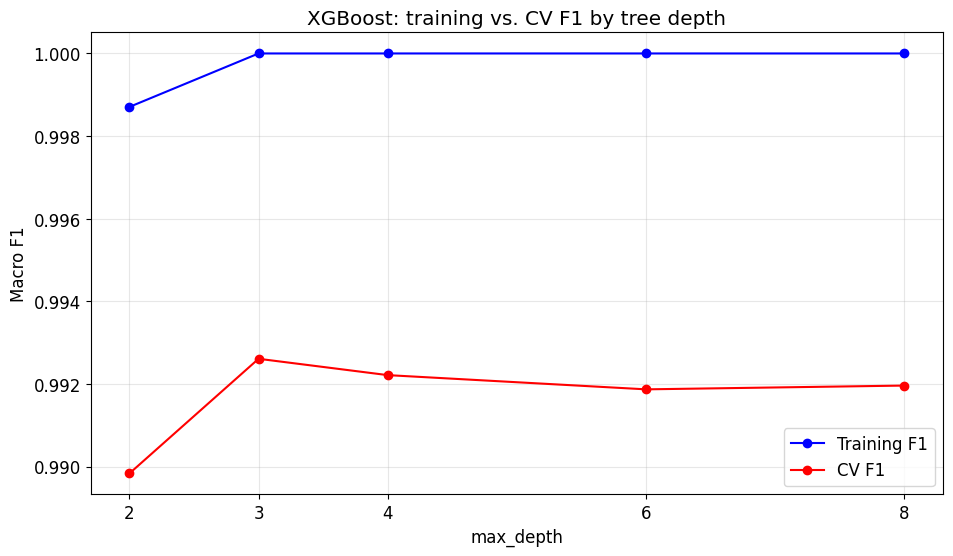

In [26]:
plt.plot(depth_results['max_depth'], depth_results['train_f1'], color='blue', marker='o', label='Training F1')
plt.plot(depth_results['max_depth'], depth_results['cv_f1'], color='red', marker='o', label='CV F1')
plt.xticks(depths)
plt.xlabel("max_depth")
plt.ylabel("Macro F1")
plt.title("XGBoost: training vs. CV F1 by tree depth")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

- Training F1 is 1.0 for every depth ≥ 3, so only CV F1 is useful here.
- **Best: `max_depth = 3`** (CV F1 0.9926). Depth 2 underfits; deeper trees don't help.
- Differences between depths 3–8 are within fold-to-fold noise.

### 7.3 Row and feature sampling

In [27]:
best_depth = depth_search.best_params_['max_depth']

sampling_search = GridSearchCV(
    XGBClassifier(n_estimators=n_trees, learning_rate=0.1, max_depth=best_depth, random_state=42),
    {'subsample': [0.7, 1.0], 'colsample_bytree': [0.5, 1.0]},
    cv=cv,
    scoring='f1_macro'
)
sampling_search.fit(X_train, y_train)

sampling_results = pd.DataFrame(sampling_search.cv_results_['params'])
sampling_results['cv_f1'] = sampling_search.cv_results_['mean_test_score']
sampling_results['cv_f1_std'] = sampling_search.cv_results_['std_test_score']
sampling_results.sort_values('cv_f1', ascending=False)

,colsample_bytree,subsample,cv_f1,cv_f1_std
0,0.5,0.7,0.993314,0.000803
2,1.0,0.7,0.993230,0.000790
1,0.5,1.0,0.992995,0.000902
3,1.0,1.0,0.992609,0.000993


- **Best: `subsample = 0.7`, `colsample_bytree = 0.5`** (CV F1 0.9933 vs. 0.9926 without sampling).
- The gain is smaller than the fold-to-fold noise.

### 7.4 Final model
Retrain on the full training set with the best parameters, then evaluate on the test set.

In [28]:
best_params = {
    'n_estimators': n_trees,
    'learning_rate': 0.1,
    'max_depth': best_depth,
    **sampling_search.best_params_,
}
print(best_params)

xgb = XGBClassifier(**best_params, random_state=42)
xgb.fit(X_train, y_train)

{'n_estimators': 300, 'learning_rate': 0.1, 'max_depth': 3, 'colsample_bytree': 0.5, 'subsample': 0.7}


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'multi:softprob'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.5
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes fr

In [29]:
xgb_test_pred = xgb.predict(X_test)
xgb_results = evaluate('XGBoost', y_test, xgb_test_pred)

print("Training accuracy:", accuracy_score(y_train, xgb.predict(X_train)))
print("Testing accuracy: ", xgb_results['Accuracy'])
print("Balanced accuracy:", xgb_results['Balanced accuracy'])
print("Macro F1:         ", xgb_results['F1'])

Training accuracy: 1.0
Testing accuracy:  0.994608195542775
Balanced accuracy: 0.994171219470542
Macro F1:          0.9945429195687753


- **Test accuracy 99.46%** (15 errors).
- Training accuracy is 100%, yet the test score stays high: many shallow, scaled-down trees generalize far better than one deep tree.

## 8. Model Comparison
### 8.1 Test set metrics

In [30]:
comparison = pd.DataFrame([log_reg_results, tree_results, xgb_results])
comparison.round(4)

,Model,Accuracy,Balanced accuracy,Precision,Recall,F1,Test errors
0,Logistic Regression,0.9925,0.9918,0.9930,0.9918,0.9924,21
1,Decision Tree,0.9723,0.9702,0.9709,0.9702,0.9705,77
2,XGBoost,0.9946,0.9942,0.9949,0.9942,0.9945,15


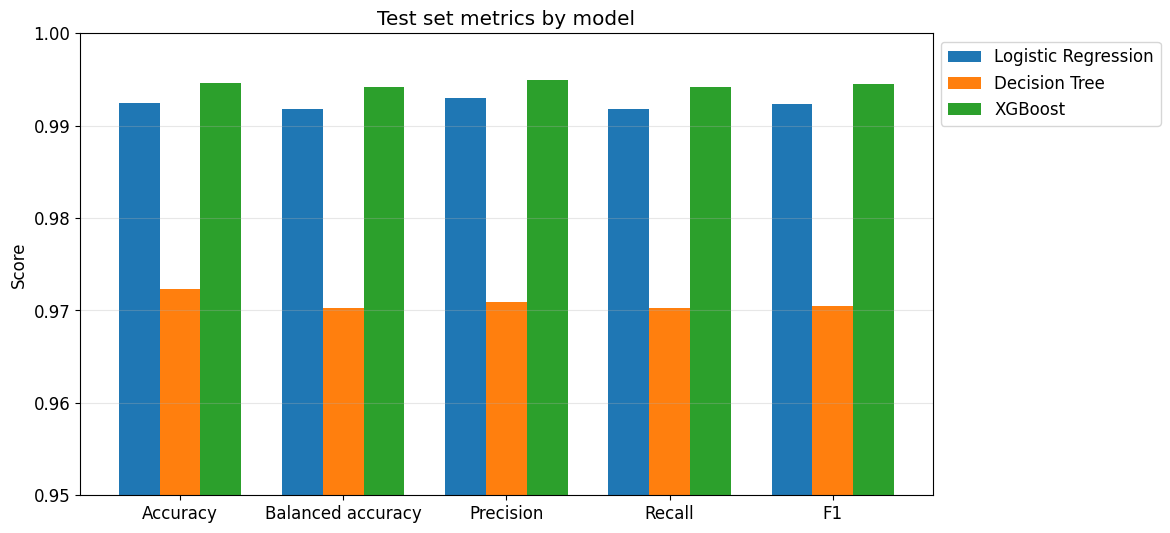

In [31]:
metrics = ['Accuracy', 'Balanced accuracy', 'Precision', 'Recall', 'F1']
bar_width = 0.25
positions = np.arange(len(metrics))

for i, row in comparison.iterrows():
    plt.bar(positions + (i - 1) * bar_width, row[metrics], width=bar_width, label=row['Model'])

plt.xticks(positions, metrics)
plt.ylim(0.95, 1.0)
plt.ylabel("Score")
plt.title("Test set metrics by model")
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

| Model | Accuracy | Balanced acc. | F1 (macro) | Test errors |
|---|---|---|---|---|
| Logistic Regression | 0.9925 | 0.9918 | 0.9924 | 21 |
| Decision Tree | 0.9723 | 0.9702 | 0.9705 | 77 |
| XGBoost | **0.9946** | **0.9942** | **0.9945** | **15** |

- **XGBoost is best on every metric.**
- vs. Decision Tree: 15 errors instead of 77 (about 80% fewer).
- vs. Logistic Regression: 15 errors instead of 21 (about 30% fewer).

### 8.2 Per-class performance
Ammonia is the smallest class, so it's checked explicitly.

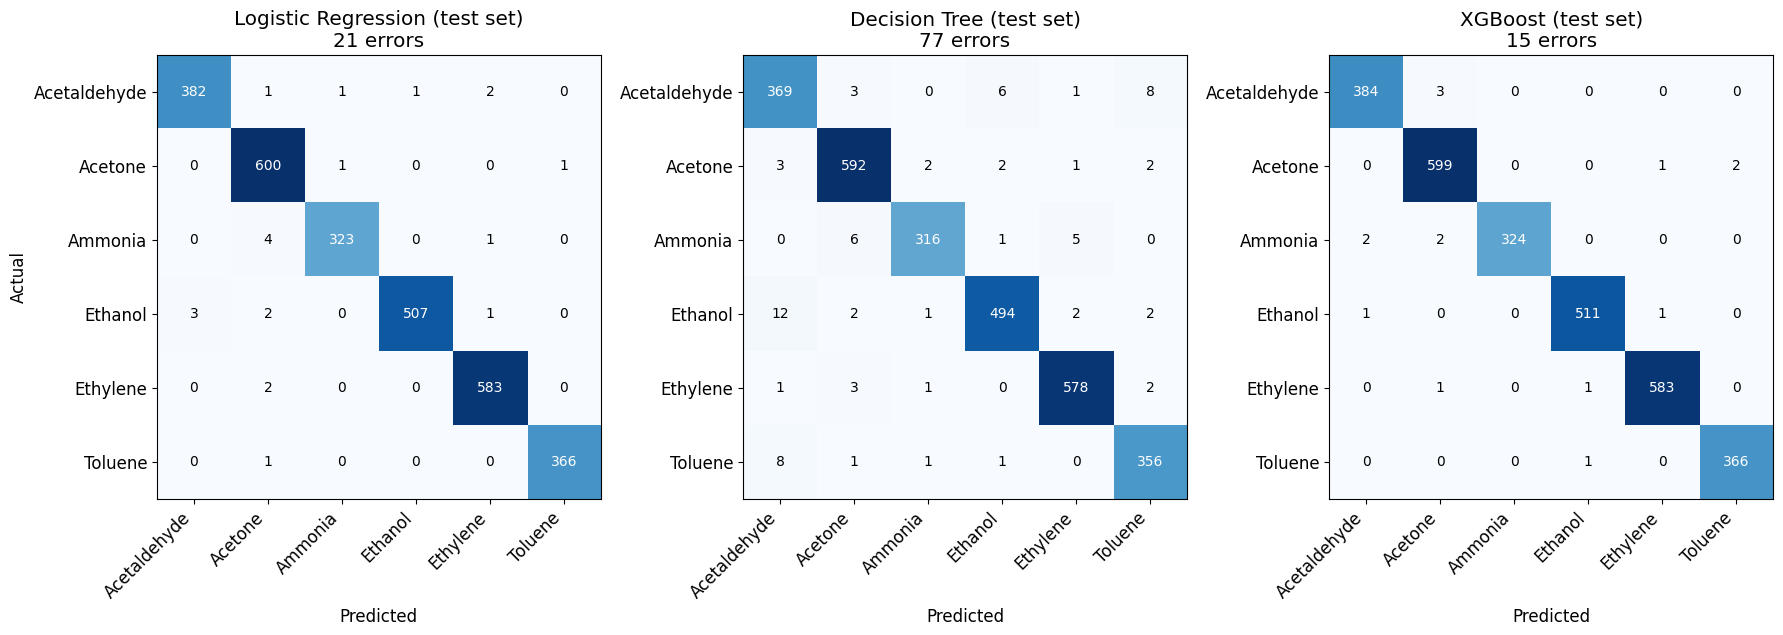

In [32]:
test_predictions = {
    'Logistic Regression': log_reg_test_pred,
    'Decision Tree': tree_test_pred,
    'XGBoost': xgb_test_pred,
}

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, pred) in zip(axes, test_predictions.items()):
    cm = confusion_matrix(y_test, pred)
    ax.imshow(cm, cmap='Blues')
    ax.set_xticks(range(len(class_names)))
    ax.set_xticklabels(class_names, rotation=45, ha='right')
    ax.set_yticks(range(len(class_names)))
    ax.set_yticklabels(class_names)
    ax.set_xlabel("Predicted")
    ax.set_title(f"{name} (test set)\n{(pred != y_test).sum()} errors")

    # Write the count inside each square
    for i in range(len(class_names)):
        for j in range(len(class_names)):
            ax.text(j, i, cm[i, j], ha='center', va='center', fontsize=10,
                    color='white' if cm[i, j] > cm.max() / 2 else 'black')

axes[0].set_ylabel("Actual")
plt.tight_layout()
plt.show()

In [33]:
per_class_f1 = pd.DataFrame({
    name: f1_score(y_test, pred, average=None) for name, pred in test_predictions.items()
}, index=class_names)
per_class_f1['test count'] = y_test.value_counts().sort_index().values
per_class_f1.sort_values('test count').round(4)

,Logistic Regression,Decision Tree,XGBoost,test count
Ammonia,0.9893,0.9738,0.9939,328
Toluene,0.9973,0.9661,0.9959,367
Acetaldehyde,0.9896,0.9462,0.9922,387
Ethanol,0.9931,0.9715,0.9961,513
Ethylene,0.9949,0.9863,0.9966,585
Acetone,0.9901,0.9793,0.9925,602


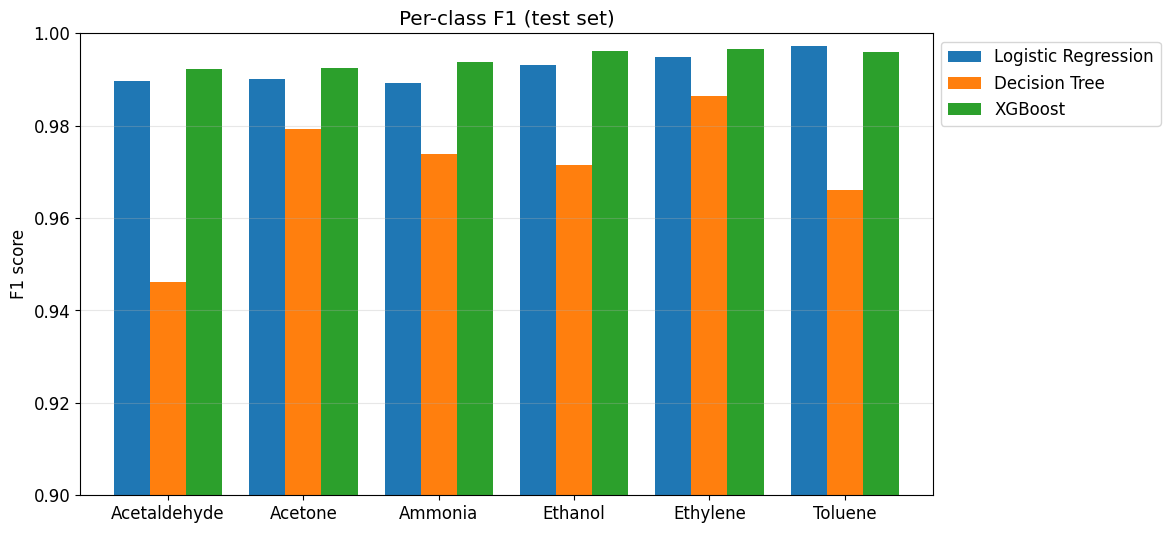

In [34]:
per_class_f1.drop(columns='test count').plot(kind='bar', width=0.8)
plt.ylim(0.9, 1.0)
plt.ylabel("F1 score")
plt.title("Per-class F1 (test set)")
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.show()

- **Ammonia (smallest class): XGBoost has the best F1 (0.9939)**, vs. 0.9893 for Logistic Regression and 0.9738 for the Decision Tree.
- XGBoost has the highest F1 on 5 of 6 gases; Logistic Regression edges it on Toluene by 1 measurement.
- The Decision Tree struggles most with Acetaldehyde (F1 0.946), confusing it with Ethanol and Toluene.

### 8.3 Is the improvement significant?
One test set can't separate models that differ by a few errors, so all models are also scored with 5-fold CV on the training data.

In [35]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000)),
    'Decision Tree': DecisionTreeClassifier(random_state=42),
    'XGBoost': XGBClassifier(**best_params, random_state=42),
}

cv_scores = {name: cross_val_score(model, X_train, y_train, cv=cv5, scoring='f1_macro')
             for name, model in cv_models.items()}

cv_summary = pd.DataFrame({
    'CV F1 mean': {name: s.mean() for name, s in cv_scores.items()},
    'CV F1 std': {name: s.std() for name, s in cv_scores.items()},
})
cv_summary.round(4)

,CV F1 mean,CV F1 std
Logistic Regression,0.9890,0.0010
Decision Tree,0.9696,0.0059
XGBoost,0.9939,0.0016


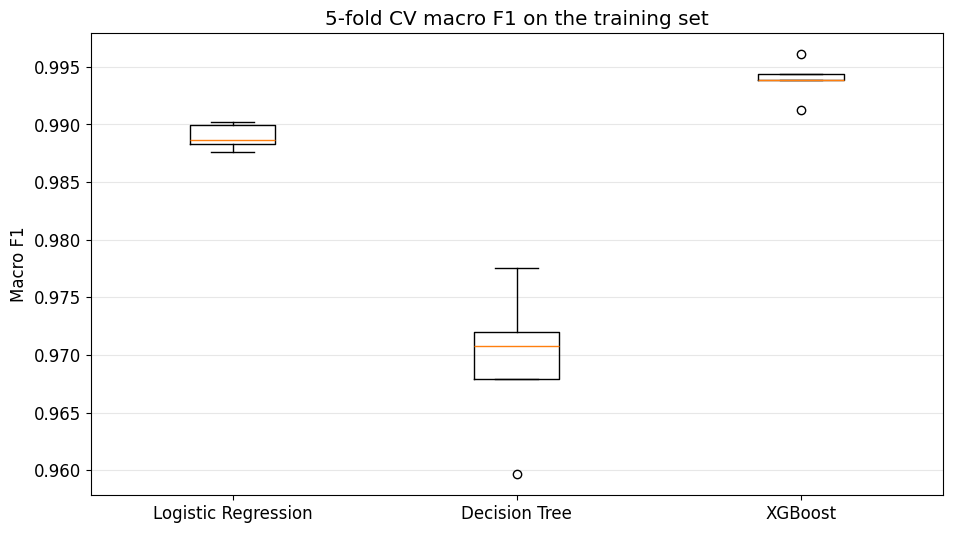

In [36]:
plt.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores.keys()))
plt.ylabel("Macro F1")
plt.title("5-fold CV macro F1 on the training set")
plt.grid(axis='y', alpha=0.3)
plt.show()

- **XGBoost beats Logistic Regression in every fold** (mean 0.9939 vs. 0.9890): a small but consistent gain.
- The Decision Tree is far behind (0.9696) and the least stable.

## 9. Conclusion

**Can XGBoost significantly improve on Logistic Regression and Decision Trees?**

- **vs. Decision Tree: yes, clearly.** About 80% fewer test errors (15 vs. 77), and better on every gas and in every CV fold. Boosting shallow trees fixes the single tree's overfitting.
- **vs. Logistic Regression: yes, but slightly.** 99.46% vs. 99.25% accuracy and ahead in every CV fold, but the baseline leaves little room.
- **Tuned parameters:** 300 trees, learning rate 0.1, depth 3, 70% of rows and 50% of features per tree.

**Limitations:**
- **Sensor drift isn't tested.** The random split mixes all 36 months, so the scores are optimistic. Training on early batches and testing on later ones would be more realistic.
- The test set is small (2,782), so a difference of a few errors isn't meaningful alone; hence the CV check.
- Gas names follow the UCI class codes, which may not match the per-batch table on the same page. This doesn't affect the comparisons.